# Method D — RGB & Colour Analysis

**Hypothesis.** A camera sensor measures only one colour per pixel (Bayer filter: a 2×2 grid G R / B G). The two missing colours are interpolated from neighbours (*demosaicing*). This creates strong links between R, G and B that repeat every 2 pixels. A generative model outputs R, G and B directly, so these links should be different.

**Tools from the practicals:** `read_rgb_image`, `get_channel`, `normalize_rgb`, `gaussian_filter` high-pass, `fft2_centered`, `spectrum_components`, `percentile_display`, `show_image` , `maximum_filter` = morphological dilation.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import maximum_filter

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from rgb_method.rgb import (load_crop, get_channel, rgb_residuals, fft2_centered,
                            spectrum_components, percentile_display, show_image,
                            extract_rgb_features, FEATURE_NAMES)

In [2]:
DATA_DIR = PROJECT_ROOT / "data"
real_paths = sorted((DATA_DIR / "real").glob("*.png"))
fake_paths = sorted((DATA_DIR / "fake").glob("*.png"))
print(f"Real images: {len(real_paths)}  |  Fake images: {len(fake_paths)}")

# Real and fake files share the same names -> they come in pairs.
ids = [p.name for p in real_paths]
print("Same names in both folders:", ids == [p.name for p in fake_paths])

Real images: 50  |  Fake images: 50
Same names in both folders: True


## 1. What a residual looks like

Residual = channel − Gaussian blur (σ = 1). The blur keeps the scene, the subtraction keeps the fine traces. We zoom on a 64×64 corner so individual pixels are visible.

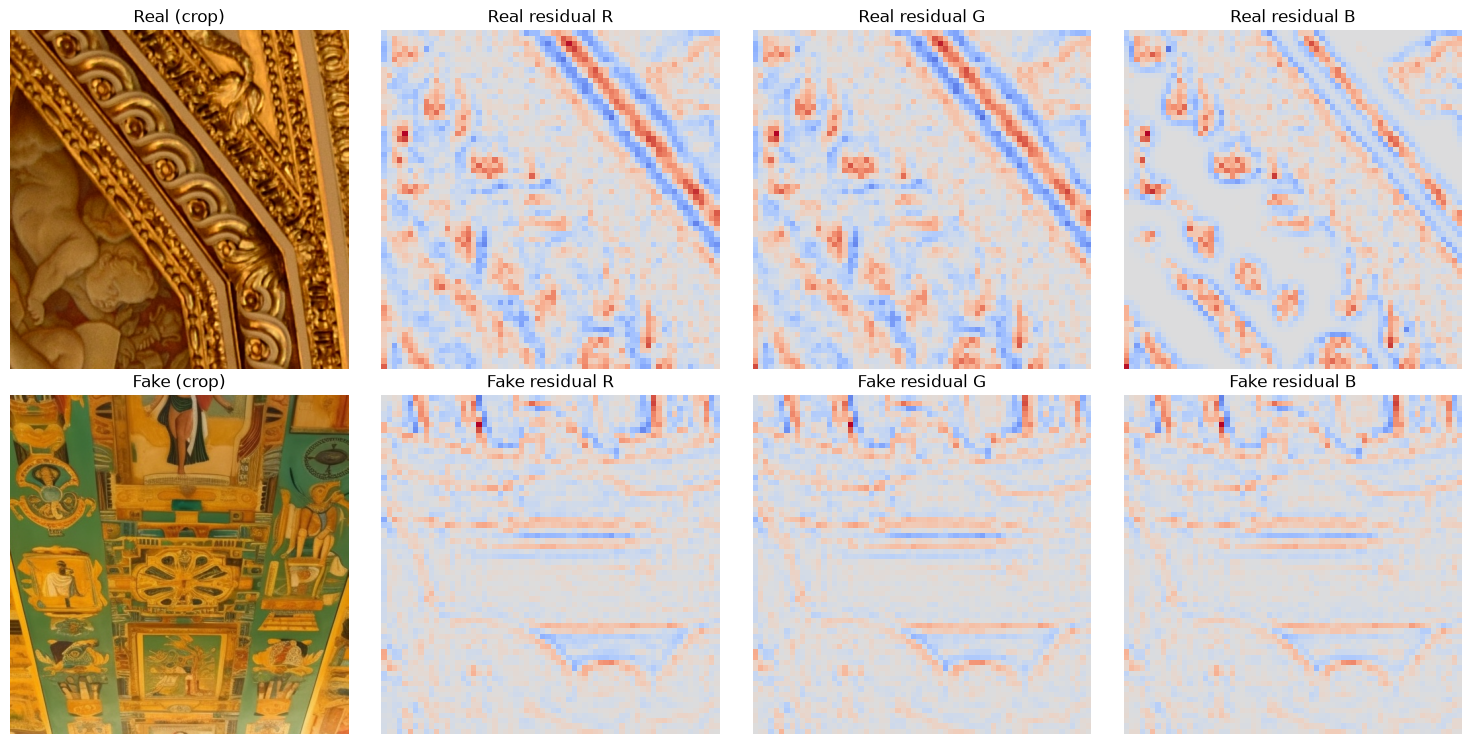

In [3]:
real = load_crop(real_paths[0]); fake = load_crop(fake_paths[0])
res_real = rgb_residuals(real); res_fake = rgb_residuals(fake)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
axes[0, 0].imshow(real); axes[0, 0].set_title("Real (crop)"); axes[0, 0].axis("off")
axes[1, 0].imshow(fake); axes[1, 0].set_title("Fake (crop)"); axes[1, 0].axis("off")
for c, name in enumerate("RGB"):
    show_image(axes[0, c + 1], res_real[:64, :64, c], f"Real residual {name}", signed=True)
    show_image(axes[1, c + 1], res_fake[:64, :64, c], f"Fake residual {name}", signed=True)
plt.tight_layout(); plt.show()

## 2. Average spectrum of the residual

For each class we average the log-magnitude spectrum of the green residual over all 50 images. Averaging removes the scene-specific content and keeps what is common to the class. A 2-pixel periodic pattern (demosaicing) appears as bright points at the **corners and edge midpoints**. We apply a morphological dilation (`maximum_filter`) so isolated peaks are easier to see.

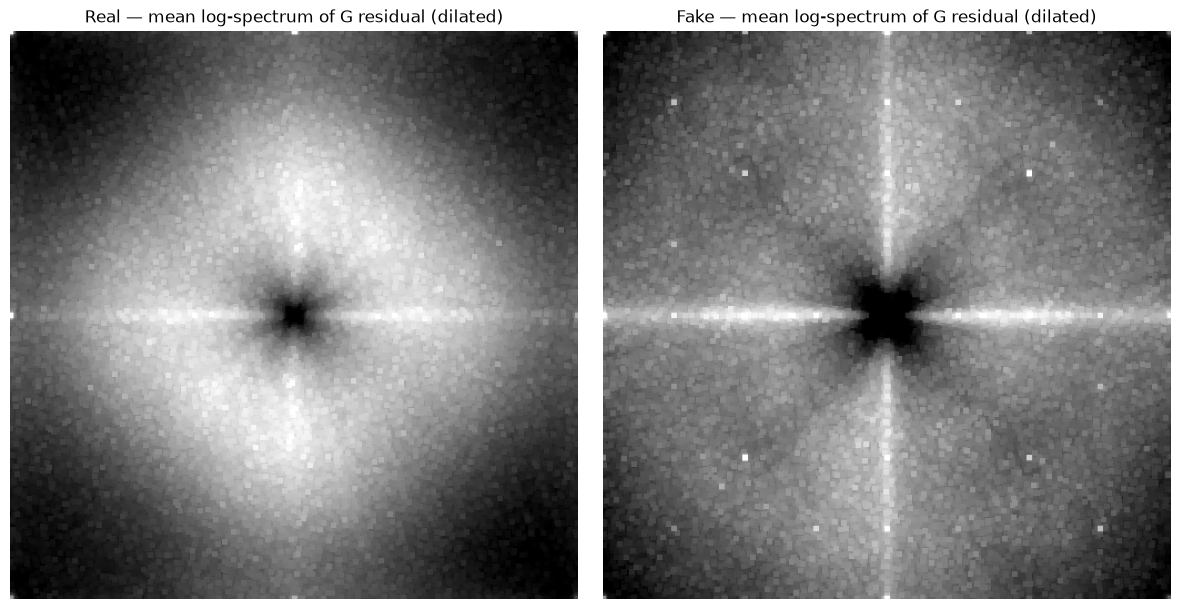

In [4]:
def mean_log_spectrum(paths, channel=1):
    acc = None
    for p in paths:
        residual = rgb_residuals(load_crop(p))[..., channel]
        _, log_mag, _ = spectrum_components(fft2_centered(residual))
        acc = log_mag if acc is None else acc + log_mag
    return acc / len(paths)

spec_real = mean_log_spectrum(real_paths)
spec_fake = mean_log_spectrum(fake_paths)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, spec, title in zip(axes, [spec_real, spec_fake], ["Real", "Fake"]):
    dilated = maximum_filter(spec, size=5)
    ax.imshow(percentile_display(dilated, 1, 99.9), cmap="gray")
    ax.set_title(f"{title} — mean log-spectrum of G residual (dilated)")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Feature extraction (22 features per image)

In [6]:
X_real = np.stack([extract_rgb_features(load_crop(p)) for p in real_paths])
X_fake = np.stack([extract_rgb_features(load_crop(p)) for p in fake_paths])

df = pd.DataFrame(np.vstack([X_real, X_fake]), columns=FEATURE_NAMES)
df.insert(0, "label", ["real"] * len(real_paths) + ["fake"] * len(fake_paths))
df.insert(0, "image_id", ids + [p.name for p in fake_paths])
df.to_csv(PROJECT_ROOT / "rgb_method" / "rgb_features.csv", index=False)

df.groupby("label")[FEATURE_NAMES].mean().T.round(4)

label,fake,real
corr_raw_RG,0.9325,0.9401
corr_raw_RB,0.8360,0.6816
corr_raw_GB,0.9413,0.7591
corr_res_RG,0.9808,0.8938
corr_res_RB,0.9652,0.8034
corr_res_GB,0.9819,0.8086
res_std_R,0.0387,0.0104
res_std_G,0.0392,0.0105
res_std_B,0.0380,0.0099
res_kurt_R,12.9184,14.4331


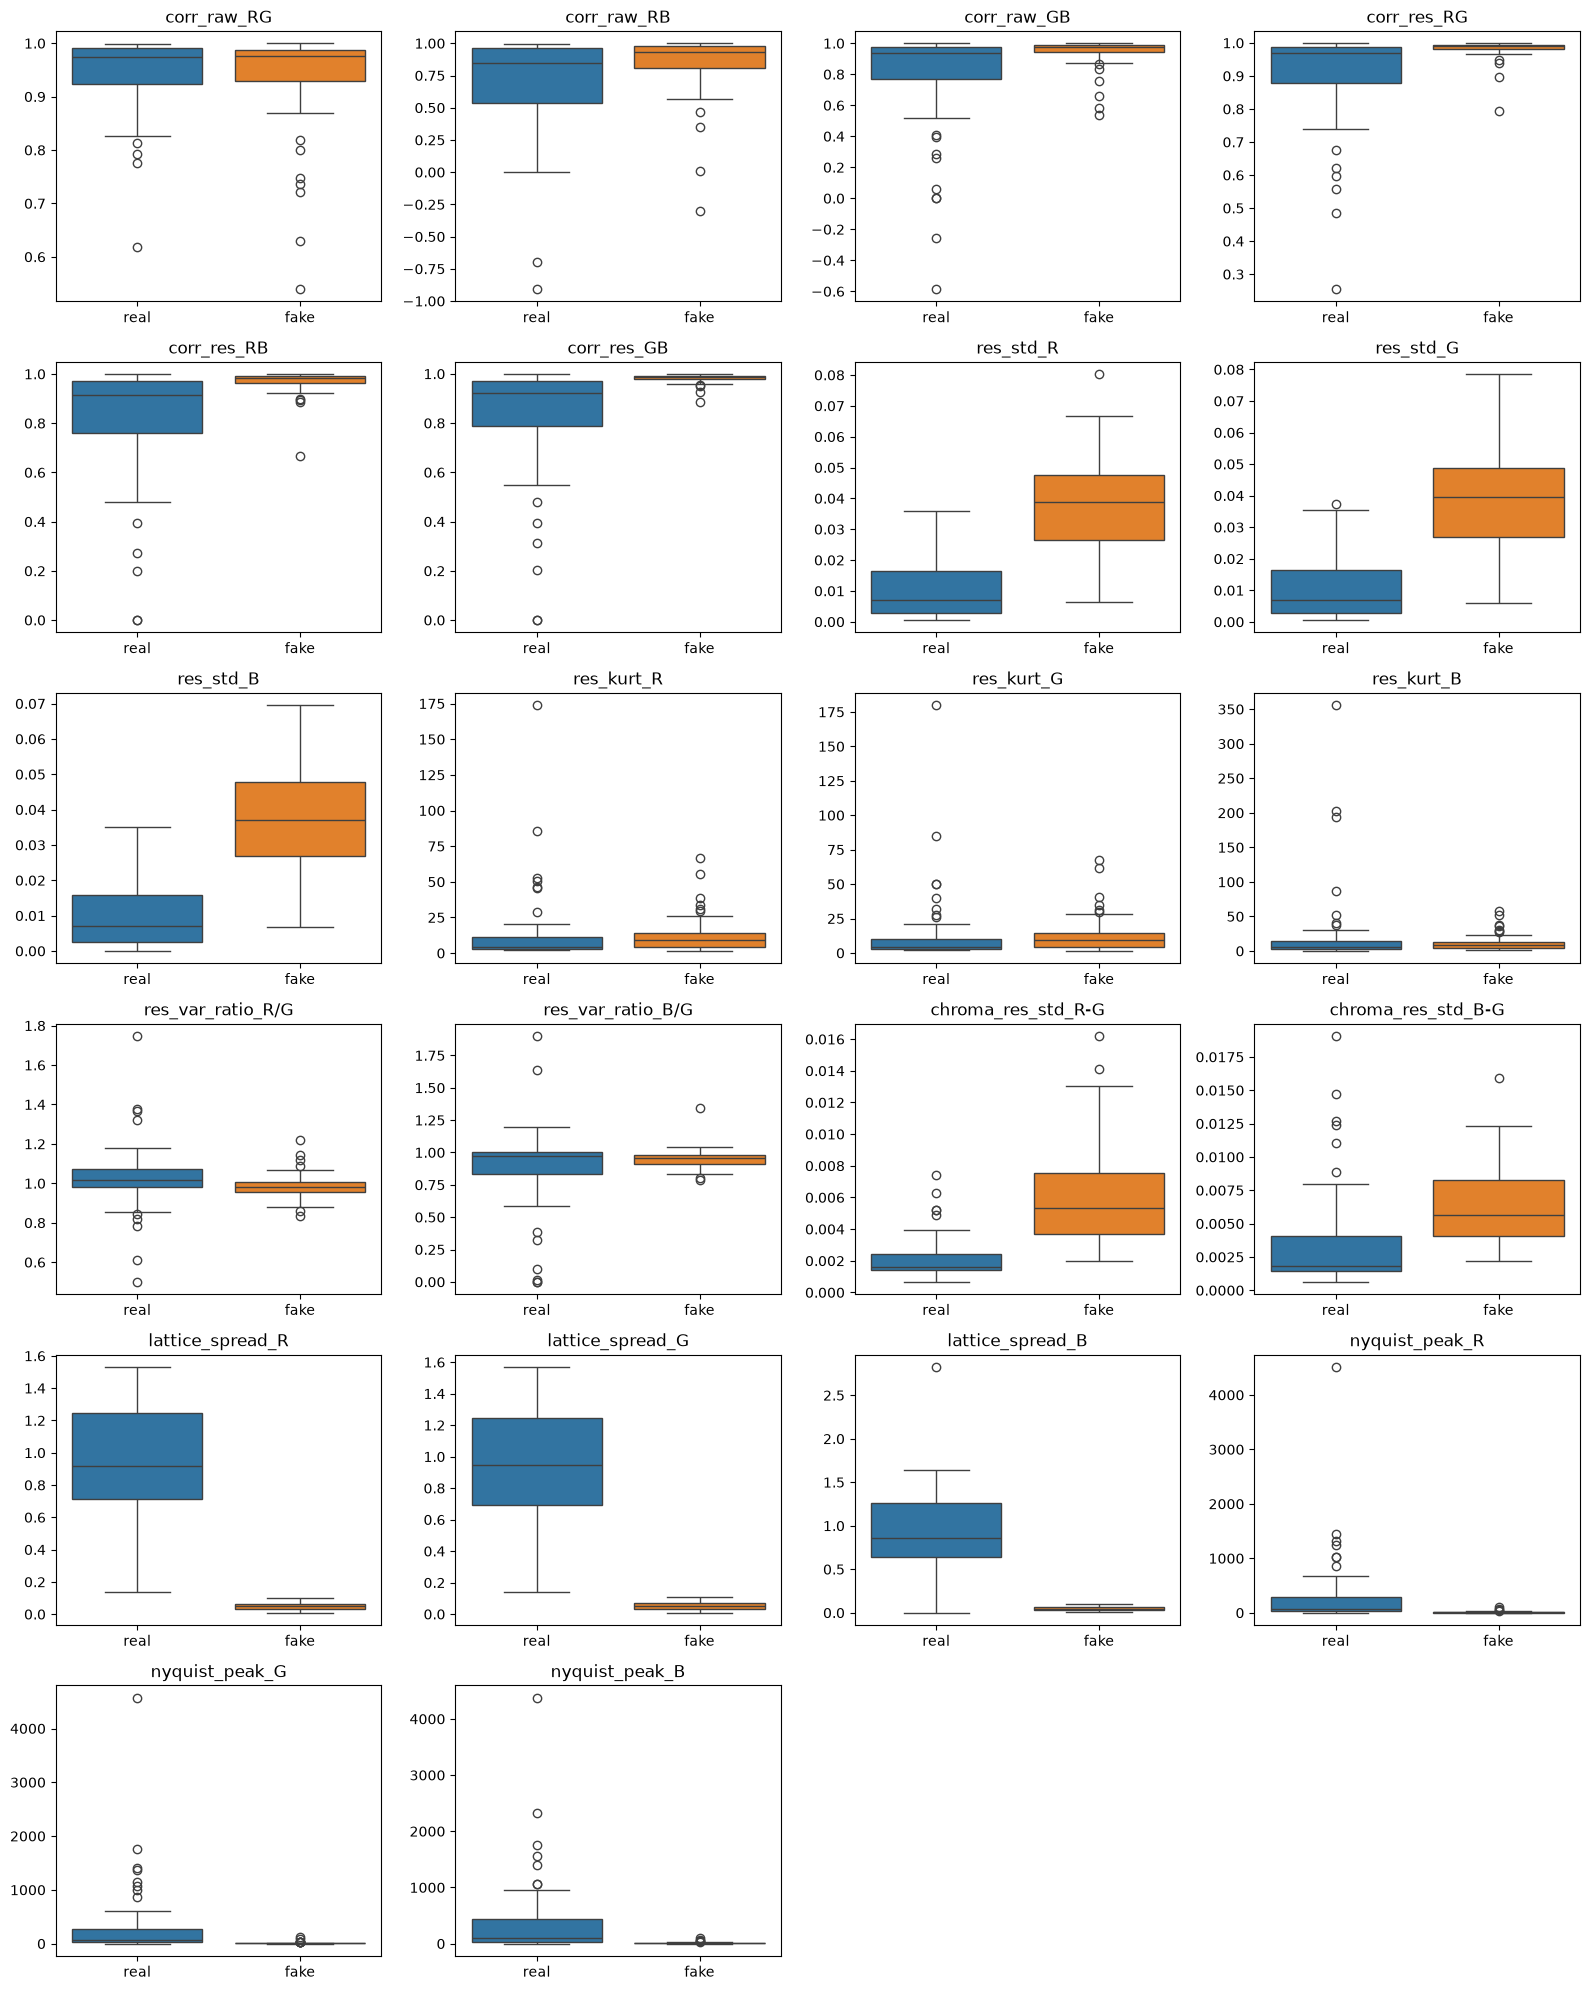

In [7]:
fig, axes = plt.subplots(6, 4, figsize=(16, 20))
for ax, name in zip(axes.ravel(), FEATURE_NAMES):
    sns.boxplot(data=df, x="label", y=name, ax=ax, hue="label", legend=False)
    ax.set_title(name); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(FEATURE_NAMES):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Intra-class vs inter-class variability (same protocol as NPR)

20 random seeds. Each time, the 50 image **ids** are split into two halves, so a real image and its fake twin always go to the same half.

Distance between two groups for one feature = |mean(A) − mean(B)| / std of that feature over all 100 images (unit-free, so features are comparable).

We expect Real–Fake ≫ Real–Real and Fake–Fake.

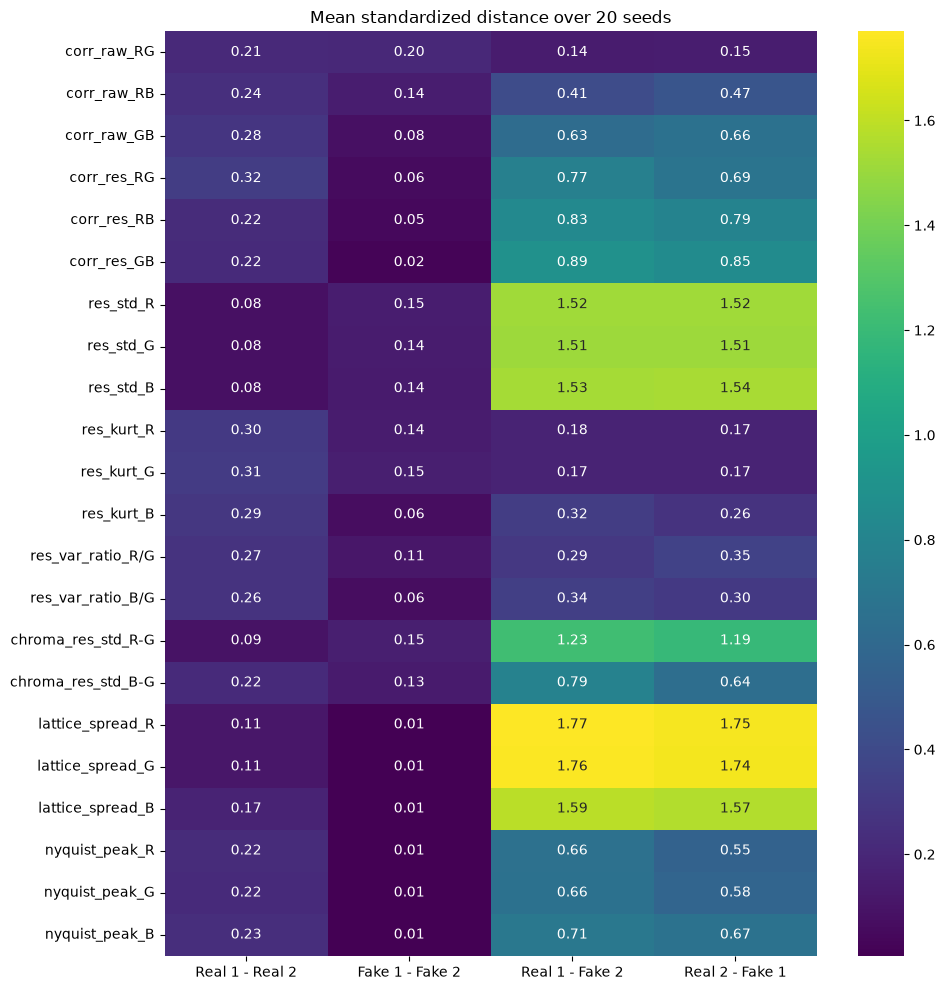

In [8]:
N_SEEDS = 20
comparisons = ["Real 1 - Real 2", "Fake 1 - Fake 2", "Real 1 - Fake 2", "Real 2 - Fake 1"]
scale = np.vstack([X_real, X_fake]).std(axis=0) + 1e-12

def distance(A, B):
    return np.abs(A.mean(axis=0) - B.mean(axis=0)) / scale

results = {c: [] for c in comparisons}
n = len(ids)
for seed in range(N_SEEDS):
    perm = np.random.default_rng(seed).permutation(n)
    h1, h2 = perm[: n // 2], perm[n // 2:]
    results["Real 1 - Real 2"].append(distance(X_real[h1], X_real[h2]))
    results["Fake 1 - Fake 2"].append(distance(X_fake[h1], X_fake[h2]))
    results["Real 1 - Fake 2"].append(distance(X_real[h1], X_fake[h2]))
    results["Real 2 - Fake 1"].append(distance(X_real[h2], X_fake[h1]))

mean_table = pd.DataFrame({c: np.mean(results[c], axis=0) for c in comparisons}, index=FEATURE_NAMES)
std_table = pd.DataFrame({c: np.std(results[c], axis=0, ddof=1) for c in comparisons}, index=FEATURE_NAMES)

plt.figure(figsize=(10, 10))
sns.heatmap(mean_table, annot=True, fmt=".2f", cmap="viridis")
plt.title("Mean standardized distance over 20 seeds")
plt.tight_layout(); plt.show()

In [9]:
ranking = mean_table.assign(
    inter=mean_table[["Real 1 - Fake 2", "Real 2 - Fake 1"]].mean(axis=1),
    intra=mean_table[["Real 1 - Real 2", "Fake 1 - Fake 2"]].mean(axis=1),
)
ranking["ratio inter/intra"] = ranking["inter"] / ranking["intra"]
ranking[["inter", "intra", "ratio inter/intra"]].sort_values("ratio inter/intra", ascending=False).round(2)

,inter,intra,ratio inter/intra
lattice_spread_R,1.76,0.06,29.73
lattice_spread_G,1.75,0.06,29.36
lattice_spread_B,1.58,0.09,17.66
res_std_B,1.53,0.11,14.37
res_std_G,1.51,0.11,13.79
res_std_R,1.52,0.11,13.70
chroma_res_std_R-G,1.21,0.12,9.87
corr_res_GB,0.87,0.12,7.24
corr_res_RB,0.81,0.13,6.13
nyquist_peak_B,0.69,0.12,5.75
